# Synthetic campaign — which strategy, and at what settings

Sweeps the routing policies over the campus map and files every run in the
[results store](../autobus-docs/docs/concepts/experiment.md), so this notebook
can be **stopped at any point without losing work** and re-run later to
continue. Nothing here needs a CARLA server.

The design review's statistical bar — a confidence-interval half-width under
5% of the mean for every KPI — lives *here*, on the synthetic map, rather than
on CARLA. CARLA's job is to show the result carries over; this is where the
result is established.

## How to run it

**Prefer a terminal over this notebook for the long stages.** Workers are
forked, and forking a process that already has threads can deadlock a child.
A script run through `run.sh` is single-threaded; a Jupyter kernel is not.
Everything below works in Jupyter and usually finishes, but for an unattended
sweep, export this to a script.

To stop: interrupt the kernel. Every trial that finished is already on disk.
To continue: re-run the same cell — it reruns only what is missing.

## Two knobs both called `max_wait_s`

They are unrelated and it matters:

| | what it is |
|---|---|
| `run_trial(max_wait_s=...)` | **passenger patience** — how long someone waits before giving up. `None` means they wait forever. |
| `WindowInsertionPolicy(max_wait_s=...)` | the **service window** — the promise the policy plans against, and refuses requests it cannot keep. |

Below they are called `PATIENCE` and `W` respectively.

## Configuration

In [1]:
from src.experiment.store import DEFAULT_RUNS_DIR

# --- The map every experiment in this project has used ------------------
# stop_density=0.5 is REQUIRED, not decorative: it makes this the 21-stop
# "campus map" every earlier result used. The generator defaults to 0.15,
# which on this seed gives 6 stops -- a map so easy that plain fixed route
# serves 100% and every comparison flattens into noise.
MAP = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
           stop_density=0.5)

# --- Where runs are filed -----------------------------------------------
# DEFAULT_RUNS_DIR is anchored to the source tree, not to the working
# directory: JupyterLab starts a kernel in the notebook's folder, and a
# relative path would file half a campaign somewhere else entirely.
RUNS = DEFAULT_RUNS_DIR

# --- Sample size ---------------------------------------------------------
# Start here; the last section reports which KPIs missed the 5% bar and
# extending is free, because the store reruns only what is missing.
SEEDS = list(range(60))

# --- Load ----------------------------------------------------------------
# 200 requests at one per 60 s, capacity 40: the settings the existing
# notebooks used, so these runs extend that work rather than replace it.
BASE_TRIAL = dict(
    max_requests=200,
    capacity=40,
    demand_interval_s=60.0,
    max_time=60000.0,
)

# --- The two regimes -----------------------------------------------------
# Measured before choosing: with PATIENCE=None every policy serves 100% and
# fulfilment rate discriminates nothing at all. At 900 s the field spreads
# from 80% to 100%, which is also where the design review's ">= 80%"
# criterion starts to mean something.
REGIMES = {
    "patient": None,
    "impatient": 900.0,
}

# --- Service windows to sweep -------------------------------------------
WINDOWS = [450.0, 600.0, 750.0, 900.0, 1200.0, 1800.0]
DEFAULT_W = 900.0

# --- Parallelism ---------------------------------------------------------
# 8 measured as the sweet spot on a 16-core machine; the work is CPU-bound
# pure Python, so hyperthreads add little. Use 1 to debug.
N_JOBS = 10

# --- Stage 3 is opt-in; it is the longest ---------------------------------
RUN_LOAD_SWEEP = False
LOAD_INTERVALS = [30.0, 45.0, 60.0, 90.0]

In [2]:
import time

import matplotlib.pyplot as plt

from src.algorithm.ConstrainedInsertionPolicy import ConstrainedInsertionPolicy
from src.algorithm.DeviatedFixedRoutePolicy import DeviatedFixedRoutePolicy
from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.MarginalCostFilterPolicy import MarginalCostFilterPolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.RideBoundedGreedyPolicy import RideBoundedGreedyPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    plot_kpi_bars,
    plot_parameter_sweep,
    run_campaign,
    summarize_results,
)
from src.experiment.store import load_frame
from src.map.graph import PlanarStreetGraph

from IPython.display import Markdown, display

graph = PlanarStreetGraph.generate(**MAP)

# The part of a run's identity that cannot be read off the arguments. The map
# is described by its generation parameters because PlanarStreetGraph does not
# retain them -- leave one out and two different maps would share an identity.
WORLD = {
    "map": "planar",
    "n_seeds": MAP["n_seeds"],
    "bounds": list(MAP["bounds"]),
    "map_seed": MAP["seed"],
    "stop_density": MAP["stop_density"],
    "backend": "MockBackend",
}

from src.map.PlanarMapProvider import PlanarMapProvider
print(f"map: {MAP['n_seeds']} seeds over {MAP['bounds'][2]:.0f} m, "
      f"seed {MAP['seed']}, {len(PlanarMapProvider(graph).get_stops())} stops")
print(f"{len(SEEDS)} seeds per configuration, n_jobs={N_JOBS}")

map: 17 seeds over 2000 m, seed 42, 21 stops
60 seeds per configuration, n_jobs=10


## The policies

All nine concrete policies. `PlaceholderPolicy` is excluded — it is a
development stub, not a strategy.

The two insertion policies are labelled with their service window, so the
window sweep in stage 2 reuses these runs rather than repeating them.

In [3]:
def window_family(windows):
    """
    Build the insertion policies at each service window.
    :param windows: Service windows in seconds.
    :return: (label, factory) pairs.
    """
    pairs = []
    for w in windows:
        pairs.append((f"Window W{w:.0f}",
                      lambda g, w=w: WindowInsertionPolicy(g, max_wait_s=w)))
        pairs.append((f"Reordering W{w:.0f}",
                      lambda g, w=w: ReorderingInsertionPolicy(
                          g, max_wait_s=w)))
    return pairs


BASELINES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Skip-stop", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Deviated", lambda g: DeviatedFixedRoutePolicy(g)),
]
GREEDY = [
    ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
    ("Marginal cost", lambda g: MarginalCostFilterPolicy(g)),
    ("Ride bounded", lambda g: RideBoundedGreedyPolicy(g)),
]
INSERTION = [("Constrained", lambda g: ConstrainedInsertionPolicy(g))]

SHOOTOUT = (BASELINES + GREEDY + INSERTION
            + window_family([DEFAULT_W]))

print(f"{len(SHOOTOUT)} policies in the shootout")
for label, _ in SHOOTOUT:
    print(" ", label)

9 policies in the shootout
  Fixed route
  Skip-stop
  Deviated
  Nearest unserved
  Marginal cost
  Ride bounded
  Constrained
  Window W900
  Reordering W900


## Calibration — how long will this take?

Times one trial of each policy so the estimate below is measured rather than
guessed. `ReorderingInsertionPolicy` dominates the cost; the fixed-route
family is nearly free.

In [4]:
def time_one(factory, patience):
    """
    Time a single trial.
    :param factory: Policy factory.
    :param patience: Passenger patience in seconds, or None.
    :return: Seconds elapsed.
    """
    from src.experiment import run_trial
    started = time.perf_counter()
    run_trial(policy_factory=factory, graph=graph, seed=0,
              max_wait_s=patience, silent=True, **BASE_TRIAL)
    return time.perf_counter() - started


per_trial = {label: time_one(f, REGIMES["impatient"]) for label, f in SHOOTOUT}
for label, seconds in sorted(per_trial.items(), key=lambda kv: -kv[1]):
    print(f"  {label:<20} {seconds:6.2f} s/trial")

stage1 = sum(per_trial.values()) * len(SEEDS) * len(REGIMES)
extra = [f"{k} W{w:.0f}" for w in WINDOWS if w != DEFAULT_W
         for k in ("Window", "Reordering")]
stage2 = (per_trial[f"Window W{DEFAULT_W:.0f}"]
          + per_trial[f"Reordering W{DEFAULT_W:.0f}"]) \
    * (len(WINDOWS) - 1) * len(SEEDS) * len(REGIMES)

print()
print(f"stage 1  ~{stage1 / 60:5.1f} min sequential  "
      f"~{stage1 / 60 / 6.8:5.1f} min at n_jobs={N_JOBS}")
print(f"stage 2  ~{stage2 / 60:5.1f} min sequential  "
      f"~{stage2 / 60 / 6.8:5.1f} min at n_jobs={N_JOBS}")
print("(already-recorded runs are skipped, so a re-run costs nothing)")

  Reordering W900        4.65 s/trial
  Window W900            1.31 s/trial
  Constrained            0.14 s/trial
  Ride bounded           0.11 s/trial
  Deviated               0.03 s/trial
  Skip-stop              0.03 s/trial
  Nearest unserved       0.03 s/trial
  Marginal cost          0.03 s/trial
  Fixed route            0.02 s/trial

stage 1  ~ 12.7 min sequential  ~  1.9 min at n_jobs=10
stage 2  ~ 59.6 min sequential  ~  8.8 min at n_jobs=10
(already-recorded runs are skipped, so a re-run costs nothing)


## Stage 1 — the shootout

Every policy, both regimes. This is the table that says which *family* wins,
and it is the evidence for setting the others aside.

In [5]:
def sweep(policies, regimes=REGIMES, **trial_overrides):
    """
    Run one campaign per regime and report what it did.
    :param policies: (label, factory) pairs.
    :param regimes: Mapping of regime name to passenger patience.
    :param trial_overrides: Trial parameters replacing BASE_TRIAL entries.
    :return: Mapping of regime name to CampaignResult.
    """
    trial = {**BASE_TRIAL, **trial_overrides}
    results = {}
    for name, patience in regimes.items():
        started = time.perf_counter()
        results[name] = run_campaign(
            policies=policies,
            seeds=SEEDS,
            world=WORLD,
            directory=RUNS,
            graph=graph,
            n_jobs=N_JOBS,
            progress=True,
            max_wait_s=patience,
            **trial,
        )
        print(f"{name:<10} ran={results[name].ran:<5} "
              f"skipped={results[name].skipped:<5} "
              f"{(time.perf_counter() - started) / 60:.1f} min")
    return results


shootout = sweep(SHOOTOUT)

campaign:   0%|          | 0/540 [00:00<?, ?it/s]

patient    ran=540   skipped=0     1.5 min


campaign:   0%|          | 0/540 [00:00<?, ?it/s]

impatient  ran=540   skipped=0     1.1 min


In [6]:
for name, result in shootout.items():
    patience = REGIMES[name]
    display(Markdown(
        f"### {name} — passenger patience "
        f"{'unlimited' if patience is None else f'{patience:.0f} s'}"))
    display(Markdown(summarize_results(result.results()).markdown))

### patient — passenger patience unlimited

| Property | Constrained | Deviated | Fixed route | Marginal cost | Nearest unserved | Reordering W900 | Ride bounded | Skip-stop | Window W900 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) |
| Cancelled requests | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) |
| Mean wait time | 1264.5 s (±2.5%) | 872.0 s (±3.9%) | 658.0 s (±0.9%) | 1195.1 s (±4.1%) | 1206.1 s (±4.4%) | 522.3 s (±1.9%) | 1094.2 s (±4.0%) | 632.6 s (±1.2%) | 535.7 s (±2.1%) |
| P90 wait time | 2861.2 s (±2.9%) | 1634.5 s (±4.4%) | 1178.6 s (±0.7%) | 3084.0 s (±8.9%) | 3142.5 s (±9.1%) | 877.9 s (±0.5%) | 2683.0 s (±4.4%) | 1130.3 s (±0.9%) | 888.5 s (±0.6%) |
| Mean ride time | 435.9 s (±2.8%) | 824.3 s (±3.8%) | 659.1 s (±1.0%) | 1081.3 s (±3.7%) | 1084.7 s (±3.7%) | 462.4 s (±1.9%) | 683.9 s (±3.4%) | 621.2 s (±1.1%) | 523.3 s (±2.4%) |
| Fulfillment rate | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Served fraction | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Throughput | 0.8 req/min (±0.7%) | 0.9 req/min (±0.7%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.6%) | 0.9 req/min (±0.6%) | 0.9 req/min (±0.6%) | 0.9 req/min (±0.7%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.5%) |
| Tick snapshots | 14451.2 (±0.7%) | 13852.6 (±0.7%) | 13901.5 (±0.3%) | 14001.8 (±0.6%) | 14011.5 (±0.6%) | 13325.1 (±0.6%) | 13961.5 (±0.7%) | 13442.7 (±0.4%) | 13460.0 (±0.5%) |
| Fulfilled (wait samples) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) |
| Min wait time | 7.0 s (±29.9%) | 5.3 s (±29.6%) | 7.1 s (±24.9%) | 6.4 s (±25.6%) | 6.5 s (±28.4%) | 4.1 s (±28.4%) | 6.0 s (±28.2%) | 6.5 s (±28.5%) | 5.5 s (±32.5%) |
| Max wait time | 5900.5 s (±6.0%) | 9681.1 s (±7.4%) | 1308.1 s (±0.1%) | 12077.5 s (±2.7%) | 12165.8 s (±2.2%) | 2758.6 s (±8.4%) | 7290.2 s (±7.6%) | 1361.4 s (±1.5%) | 2925.3 s (±8.8%) |
| Min ride time | 5.8 s (±12.6%) | 7.3 s (±12.9%) | 8.6 s (±13.1%) | 5.9 s (±12.4%) | 5.9 s (±12.4%) | 6.7 s (±17.4%) | 5.8 s (±12.1%) | 8.5 s (±13.2%) | 6.5 s (±17.1%) |
| Max ride time | 3619.6 s (±6.7%) | 9582.7 s (±7.6%) | 1305.8 s (±0.1%) | 11865.2 s (±3.0%) | 11954.7 s (±2.3%) | 2537.0 s (±7.0%) | 6597.9 s (±7.8%) | 1296.6 s (±0.3%) | 2592.1 s (±5.2%) |

### impatient — passenger patience 900 s

| Property | Constrained | Deviated | Fixed route | Marginal cost | Nearest unserved | Reordering W900 | Ride bounded | Skip-stop | Window W900 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 112.0 (±1.4%) | 148.8 (±1.1%) | 137.1 (±1.0%) | 146.8 (±1.4%) | 147.0 (±1.4%) | 187.6 (±0.6%) | 129.2 (±1.5%) | 149.6 (±1.1%) | 186.9 (±0.6%) |
| Cancelled requests | 88.0 (±1.8%) | 51.2 (±3.2%) | 62.9 (±2.2%) | 53.2 (±3.8%) | 53.0 (±3.8%) | 12.4 (±9.0%) | 70.8 (±2.7%) | 50.4 (±3.2%) | 13.1 (±7.9%) |
| Mean wait time | 393.7 s (±1.5%) | 368.0 s (±2.0%) | 451.0 s (±1.5%) | 299.7 s (±1.7%) | 299.6 s (±1.6%) | 461.8 s (±1.3%) | 353.4 s (±1.8%) | 456.8 s (±1.1%) | 469.2 s (±1.2%) |
| P90 wait time | 762.2 s (±1.1%) | 726.5 s (±1.4%) | 809.0 s (±0.7%) | 627.2 s (±1.9%) | 629.4 s (±1.7%) | 843.7 s (±0.5%) | 715.7 s (±1.5%) | 805.2 s (±0.6%) | 854.3 s (±0.3%) |
| Mean ride time | 222.8 s (±2.6%) | 757.1 s (±4.4%) | 656.7 s (±1.2%) | 1118.0 s (±4.4%) | 1120.6 s (±4.5%) | 458.7 s (±2.1%) | 534.7 s (±3.8%) | 597.8 s (±1.2%) | 529.2 s (±2.4%) |
| Fulfillment rate | 56.0 % (±1.4%) | 74.4 % (±1.1%) | 68.6 % (±1.0%) | 73.4 % (±1.4%) | 73.5 % (±1.4%) | 93.8 % (±0.6%) | 64.6 % (±1.5%) | 74.8 % (±1.1%) | 93.4 % (±0.6%) |
| Served fraction | 56.0 % (±1.4%) | 74.4 % (±1.1%) | 68.6 % (±1.0%) | 73.4 % (±1.4%) | 73.5 % (±1.4%) | 93.8 % (±0.6%) | 64.6 % (±1.5%) | 74.8 % (±1.1%) | 93.4 % (±0.6%) |
| Throughput | 0.5 req/min (±1.4%) | 0.7 req/min (±1.1%) | 0.6 req/min (±1.1%) | 0.7 req/min (±1.4%) | 0.7 req/min (±1.4%) | 0.9 req/min (±0.7%) | 0.6 req/min (±1.5%) | 0.7 req/min (±1.1%) | 0.9 req/min (±0.7%) |
| Tick snapshots | 12825.0 (±0.2%) | 13088.3 (±0.3%) | 13417.1 (±0.5%) | 13000.7 (±0.4%) | 12998.7 (±0.4%) | 13106.0 (±0.4%) | 12936.5 (±0.3%) | 13122.5 (±0.3%) | 13189.8 (±0.4%) |
| Fulfilled (wait samples) | 112.0 (±1.4%) | 148.8 (±1.1%) | 137.1 (±1.0%) | 146.8 (±1.4%) | 147.0 (±1.4%) | 187.6 (±0.6%) | 129.2 (±1.5%) | 149.6 (±1.1%) | 186.9 (±0.6%) |
| Min wait time | 7.4 s (±25.8%) | 6.0 s (±29.4%) | 7.1 s (±24.9%) | 5.3 s (±30.4%) | 5.2 s (±29.3%) | 4.6 s (±31.6%) | 6.8 s (±22.9%) | 6.6 s (±27.2%) | 4.7 s (±32.0%) |
| Max wait time | 888.9 s (±0.3%) | 884.1 s (±0.5%) | 893.7 s (±0.1%) | 875.7 s (±0.7%) | 876.6 s (±0.7%) | 897.1 s (±0.1%) | 886.4 s (±0.3%) | 894.7 s (±0.1%) | 897.3 s (±0.0%) |
| Min ride time | 7.1 s (±12.4%) | 8.6 s (±11.9%) | 12.4 s (±21.5%) | 8.0 s (±9.3%) | 8.1 s (±9.4%) | 6.3 s (±14.3%) | 7.8 s (±14.7%) | 10.5 s (±15.1%) | 6.5 s (±13.9%) |
| Max ride time | 1423.9 s (±8.4%) | 7683.1 s (±9.9%) | 1303.2 s (±0.2%) | 11496.0 s (±3.2%) | 11504.6 s (±3.3%) | 2367.8 s (±6.4%) | 4380.0 s (±8.8%) | 1279.0 s (±0.5%) | 2565.1 s (±4.9%) |

### Reading it

The `impatient` table is the one that discriminates. With unlimited patience
every policy eventually serves everyone, so **fulfilment rate is pinned at
100% and says nothing** — which is exactly why both regimes are run.

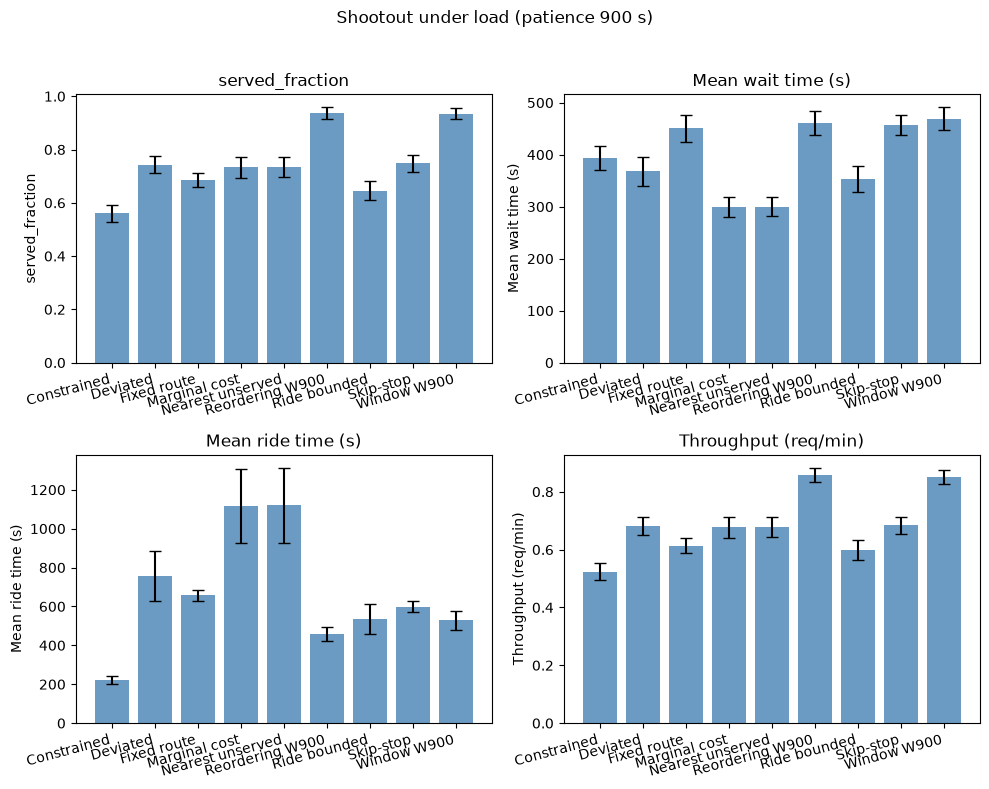

In [7]:
fig = plot_kpi_bars(
    shootout["impatient"].results(),
    fields=["served_fraction", "mean_wait_time", "mean_ride_time",
            "throughput"],
    title="Shootout under load (patience 900 s)",
)
plt.show()

## Stage 2 — the service window

Only the insertion family has a window to tune. `W900` already ran in
stage 1, so the store skips it here.

In [8]:
window_sweep = sweep(window_family(WINDOWS))

campaign:   0%|          | 0/720 [00:00<?, ?it/s]

patient    ran=600   skipped=120   6.7 min


campaign:   0%|          | 0/720 [00:00<?, ?it/s]

impatient  ran=600   skipped=120   3.9 min


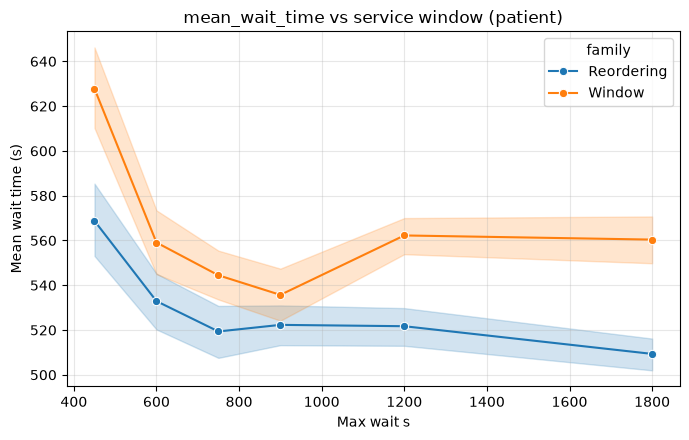

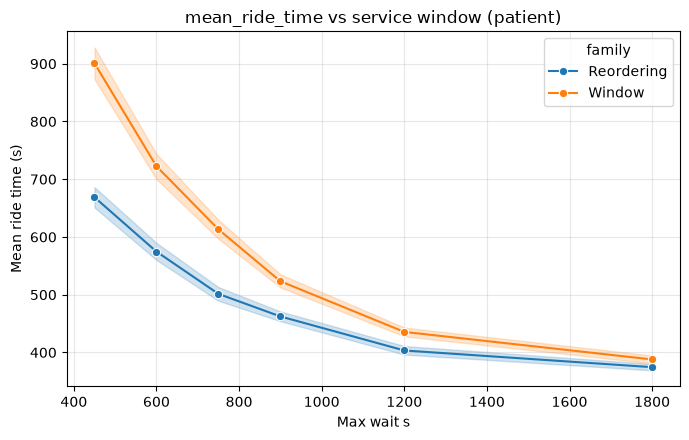

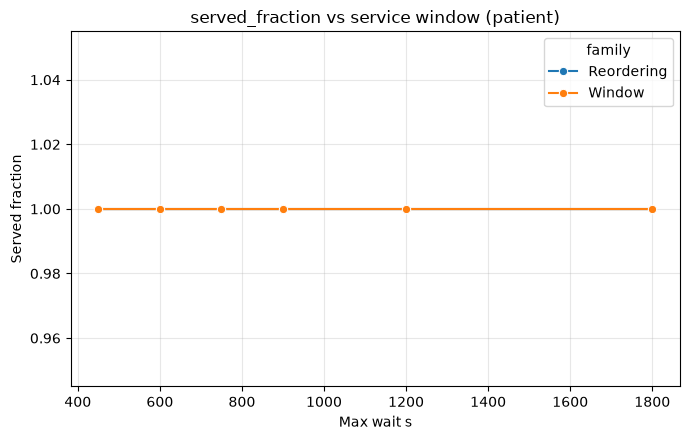

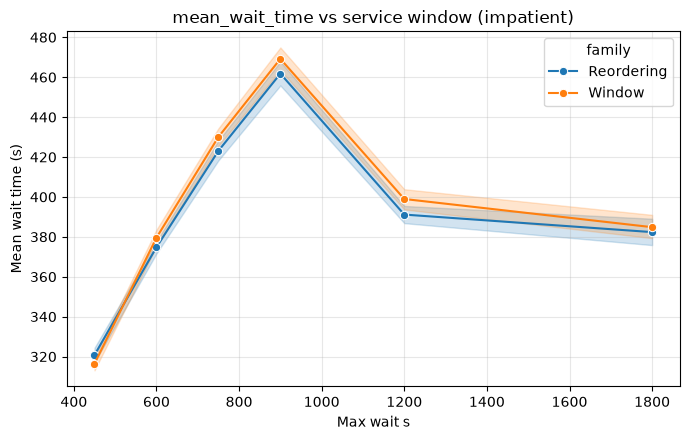

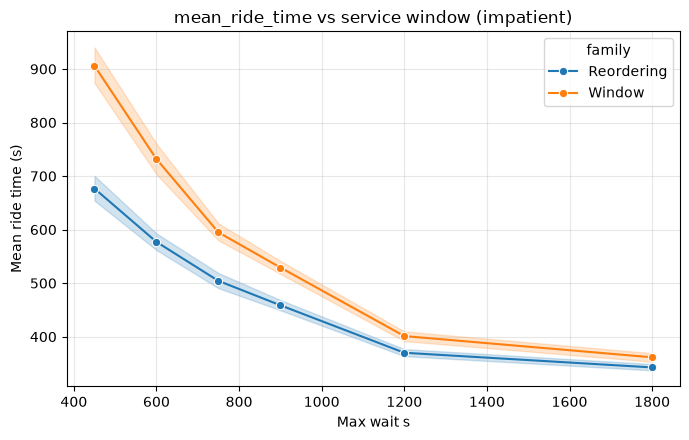

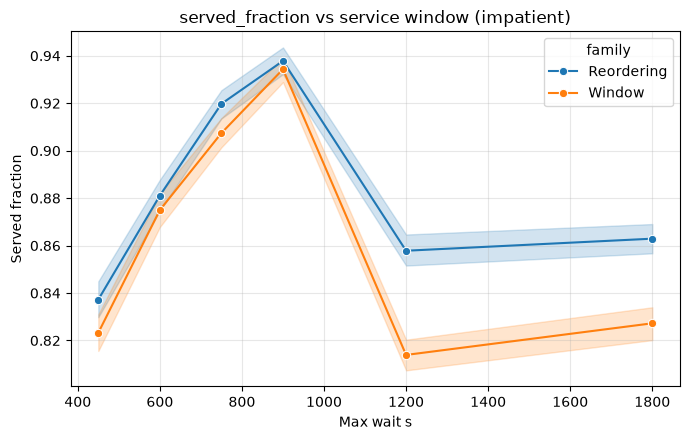

In [9]:
frame = load_frame(RUNS)
frame = frame[
    (frame["identity.world.map_seed"] == MAP["seed"])
    & (frame["identity.trial.max_requests"] == BASE_TRIAL["max_requests"])
    & (frame["identity.trial.demand_interval_s"]
       == BASE_TRIAL["demand_interval_s"])
    & frame["identity.policy_params.max_wait_s"].notna()
].copy()
# One line per policy family rather than per label, so the window becomes the
# x axis instead of nine separate columns.
frame["family"] = frame["identity.policy_class"].str.replace(
    "InsertionPolicy", "", regex=False)

for patience, label in ((None, "patient"), (900.0, "impatient")):
    subset = frame[frame["identity.trial.max_wait_s"].isna()
                   if patience is None
                   else frame["identity.trial.max_wait_s"] == patience]
    if subset.empty:
        continue
    for metric in ("kpi.mean_wait_time", "kpi.mean_ride_time",
                   "kpi.served_fraction"):
        plot_parameter_sweep(
            subset,
            x="identity.policy_params.max_wait_s",
            y=metric,
            hue="family",
            title=f"{metric.split('.')[-1]} vs service window ({label})",
        )
        plt.show()

## Stage 3 — load (optional)

How each leader degrades as demand outpaces the bus. Set `RUN_LOAD_SWEEP` in
the configuration cell to enable; it is the longest stage.

In [10]:
if RUN_LOAD_SWEEP:
    for interval in LOAD_INTERVALS:
        print(f"--- one request every {interval:.0f} s ---")
        sweep(window_family([DEFAULT_W]) + [BASELINES[0]],
              demand_interval_s=interval)
else:
    print("RUN_LOAD_SWEEP is off")

RUN_LOAD_SWEEP is off


## Did we meet the statistical bar?

The design review asks for a confidence-interval half-width below **5% of the
mean** on every KPI. This reports what was achieved and how many seeds each
shortfall would need.

Extending is free: raise `SEEDS` in the configuration cell and re-run stage 1.
Everything already recorded is skipped.

In [11]:
import math
import statistics

from scipy import stats

METRICS = {
    "served fraction": lambda r: r.kpi.served_fraction,
    "mean wait": lambda r: r.kpi.mean_wait_time,
    "mean ride": lambda r: r.kpi.mean_ride_time,
    "throughput": lambda r: r.kpi.throughput,
}


def ci_report(results, confidence=0.95):
    """
    Report the achieved CI half-width per policy and KPI.
    :param results: Policy label to trial results.
    :param confidence: Confidence level.
    :return: Markdown table.
    """
    lines = ["| policy | KPI | mean | CI half | % of mean | seeds for 5% |",
             "| --- | --- | --- | --- | --- | --- |"]
    for label, runs in sorted(results.items()):
        for name, get in METRICS.items():
            values = [get(r) for r in runs if get(r) is not None]
            n = len(values)
            if n < 2:
                continue
            mean = statistics.fmean(values)
            sd = statistics.stdev(values)
            if mean == 0 or sd == 0:
                lines.append(f"| {label} | {name} | {mean:.3g} | 0 | 0.0% | "
                             f"met |")
                continue
            half = stats.t.ppf(1 - (1 - confidence) / 2, n - 1) * sd / n ** 0.5
            pct = 100 * half / abs(mean)
            need = "met" if pct <= 5 else str(math.ceil(n * (pct / 5) ** 2))
            lines.append(f"| {label} | {name} | {mean:.3g} | {half:.3g} | "
                         f"{pct:.1f}% | {need} |")
    return "\n".join(lines)


display(Markdown("### Under load (the regime that discriminates)"))
display(Markdown(ci_report(shootout["impatient"].results())))

### Under load (the regime that discriminates)

| policy | KPI | mean | CI half | % of mean | seeds for 5% |
| --- | --- | --- | --- | --- | --- |
| Constrained | served fraction | 0.56 | 0.00801 | 1.4% | met |
| Constrained | mean wait | 394 | 5.95 | 1.5% | met |
| Constrained | mean ride | 223 | 5.79 | 2.6% | met |
| Constrained | throughput | 0.524 | 0.00757 | 1.4% | met |
| Deviated | served fraction | 0.744 | 0.00811 | 1.1% | met |
| Deviated | mean wait | 368 | 7.18 | 2.0% | met |
| Deviated | mean ride | 757 | 33.6 | 4.4% | met |
| Deviated | throughput | 0.682 | 0.00784 | 1.1% | met |
| Fixed route | served fraction | 0.686 | 0.0069 | 1.0% | met |
| Fixed route | mean wait | 451 | 6.72 | 1.5% | met |
| Fixed route | mean ride | 657 | 7.9 | 1.2% | met |
| Fixed route | throughput | 0.613 | 0.00689 | 1.1% | met |
| Marginal cost | served fraction | 0.734 | 0.0101 | 1.4% | met |
| Marginal cost | mean wait | 300 | 5 | 1.7% | met |
| Marginal cost | mean ride | 1.12e+03 | 49.5 | 4.4% | met |
| Marginal cost | throughput | 0.678 | 0.00944 | 1.4% | met |
| Nearest unserved | served fraction | 0.735 | 0.00995 | 1.4% | met |
| Nearest unserved | mean wait | 300 | 4.79 | 1.6% | met |
| Nearest unserved | mean ride | 1.12e+03 | 50.3 | 4.5% | met |
| Nearest unserved | throughput | 0.679 | 0.0093 | 1.4% | met |
| Reordering W900 | served fraction | 0.938 | 0.00561 | 0.6% | met |
| Reordering W900 | mean wait | 462 | 5.99 | 1.3% | met |
| Reordering W900 | mean ride | 459 | 9.55 | 2.1% | met |
| Reordering W900 | throughput | 0.859 | 0.0064 | 0.7% | met |
| Ride bounded | served fraction | 0.646 | 0.00965 | 1.5% | met |
| Ride bounded | mean wait | 353 | 6.36 | 1.8% | met |
| Ride bounded | mean ride | 535 | 20.3 | 3.8% | met |
| Ride bounded | throughput | 0.599 | 0.00876 | 1.5% | met |
| Skip-stop | served fraction | 0.748 | 0.0081 | 1.1% | met |
| Skip-stop | mean wait | 457 | 4.89 | 1.1% | met |
| Skip-stop | mean ride | 598 | 7.43 | 1.2% | met |
| Skip-stop | throughput | 0.684 | 0.00782 | 1.1% | met |
| Window W900 | served fraction | 0.934 | 0.00519 | 0.6% | met |
| Window W900 | mean wait | 469 | 5.81 | 1.2% | met |
| Window W900 | mean ride | 529 | 12.5 | 2.4% | met |
| Window W900 | throughput | 0.85 | 0.00624 | 0.7% | met |

## What is now in the store

Everything above, plus anything recorded earlier — including the CARLA runs.
`notebooks/results.ipynb` reads the same store and needs none of this to have
just run.

In [12]:
inventory = load_frame(RUNS)
print(f"{len(inventory)} runs on disk")
by_world = inventory.groupby(
    ["identity.world.backend", "identity.policy"]
).size().sort_values(ascending=False)
display(by_world.to_frame("runs"))

2312 runs on disk


runs
identity.world.backend identity.policy       
MockBackend            Deviated           120
                       Constrained        120
                       Fixed route        120
                       Reordering W1200   120
                       Nearest unserved   120
                       Marginal cost      120
                       Ride bounded       120
                       Skip-stop          120
                       Window W1200       120
                       Reordering W1800   120
                       Reordering W450    120
                       Reordering W600    120
                       Reordering W750    120
                       Reordering W900    120
                       Window W450        120
                       Window W600        120
                       Window W750        120
                       Window W1800       120
                       Window W900        120
CarlaBackend           Reordering          14
                       Window              10
                       Fixed route          8